In [1]:
from pathlib import Path
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from skimage.feature import hog

from sklearn.base import clone
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    confusion_matrix, classification_report,
)

%pip install "opencv-python<5"
from src.preprocess import preprocess_kdef_image

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2.1 Indexing KDEF images

In [2]:
EMOTIONS = {
    "AF": "afraid",
    "AN": "angry",
    "DI": "disgust",
    "HA": "happy",
    "NE": "neutral",
    "SA": "sad",
    "SU": "surprise",
}

POSES = {
    "FL": "full_left",
    "HL": "half_left",
    "S":  "straight",
    "HR": "half_right",
    "FR": "full_right",
}

# KDEF emotion label to FER2013 label map
KDEF_TO_FER = {
    "angry": 0, "disgust": 1, "afraid": 2, "happy": 3,
    "sad": 4, "surprise": 5, "neutral": 6,
}

emotionDict = {
    0: 'Angry', 1: 'Disgust', 2: 'Fear', 3: 'Happy',
    4: 'Sad', 5: 'Surprise', 6: 'Neutral',
}
class_names = [emotionDict[i] for i in range(7)]

ROOT = Path("data/KDEF_and_AKDEF/KDEF/")

records = []
for img_path in ROOT.rglob("*.JPG"):
    stem = img_path.stem
    
    for emotion_code in EMOTIONS:
        
        if stem[4:].startswith(emotion_code):
            pose_code = stem[4 + len(emotion_code):]
            
            if pose_code in POSES:
                records.append({
                    "path": str(img_path),
                    "acquisition": stem[0],   # session A or B
                    "subject": stem[1:4],  
                    "emotion": EMOTIONS[emotion_code],
                    "pose": POSES[pose_code],
                })
                
            break

df = pd.DataFrame(records)
print("All KDEF images:", len(df))

All KDEF images: 4898


## 2.2 80/20 Split frontal images
Also is subject independent! 

In [3]:
with open("auxFiles/kdef_subject_split.pkl", "rb") as f:
    split_data = pickle.load(f)

train_subjects = set(split_data["train_subjects"])
test_subjects = set(split_data["test_subjects"])

# Selection filter for frontal images
frontal = df[df["pose"] == "straight"]

train_df = frontal[frontal["subject"].isin(train_subjects)].reset_index(drop=True)
test_df = frontal[frontal["subject"].isin(test_subjects)].reset_index(drop=True)

# Subject independence check: no identity may be in both sets
assert train_subjects.isdisjoint(test_subjects)
assert set(train_df["subject"]).isdisjoint(set(test_df["subject"]))

n_subj = len(train_subjects) + len(test_subjects)
print(f"Train subjects: {len(train_subjects)} ({len(train_subjects) / n_subj:.0%})")
print(f"Test subjects : {len(test_subjects)} ({len(test_subjects) / n_subj:.0%})")
print("Train images  :", len(train_df))
print("Test images   :", len(test_df))
print()
print(pd.crosstab(
    frontal["emotion"],
    frontal["subject"].isin(train_subjects).map({True: "train", False: "test"})))

Train subjects: 56 (80%)
Test subjects : 14 (20%)
Train images  : 784
Test images   : 196

subject   test  train
emotion              
afraid      28    112
angry       28    112
disgust     28    112
happy       28    112
neutral     28    112
sad         28    112
surprise    28    112


## 2.3 Preprocessing step 
The following steps are done below: 
- preprocess kdef image detects face
- Crops with a margin
- converts to grayscale and resizes to 48x48
- Rescaled to [0,255] such that they match FER2013 pixel range for training HOG pipeline

In [4]:
def load_split(dataFrame):
    images, labels, subjects = [], [], []
    
    for _, row in dataFrame.iterrows():
        try:
            img = preprocess_kdef_image(row["path"])
        except ValueError as e:
            print("Skipped:", e)
            continue
    
        images.append(img * 255.0)
        labels.append(KDEF_TO_FER[row["emotion"]])
        subjects.append(row["subject"])
    
    return np.array(images), np.array(labels), np.array(subjects)


X_train_img, y_train, groups_train = load_split(train_df)
X_test_img, y_test, groups_test = load_split(test_df)

print("Train:", X_train_img.shape, " Test:", X_test_img.shape)

Train: (784, 48, 48)  Test: (196, 48, 48)


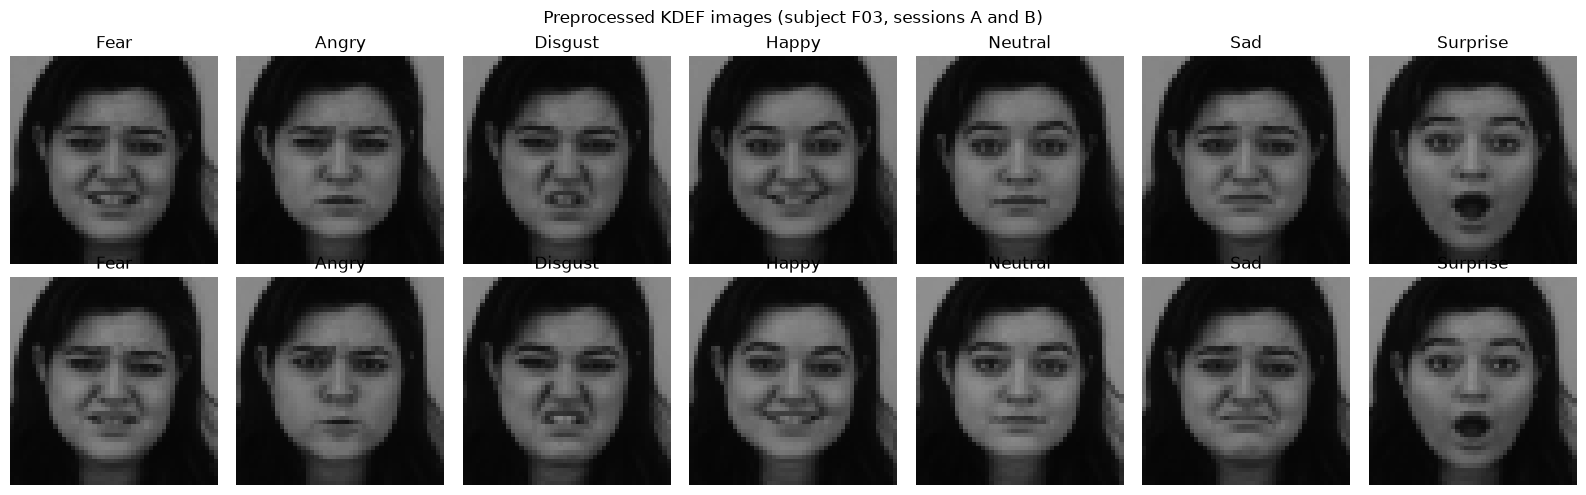

In [5]:
# Preprocessed samples
subj = groups_train[10]
idx = np.where(groups_train == subj)[0][:14]

fig, axes = plt.subplots(2, 7, figsize=(16, 5))
for ax, i in zip(axes.ravel(), idx):
    ax.imshow(X_train_img[i], cmap="gray", vmin=0, vmax=255)
    ax.set_title(emotionDict[y_train[i]])
    ax.axis("off")
    
fig.suptitle(f"Preprocessed KDEF images (subject {subj}, sessions A and B)")
plt.tight_layout()
plt.show()

## 2.4 Feature Extraction: HOG

In [6]:
def extractHOG(images):
    hog_features = []
    for img in images:
        features = hog(
            img,
            orientations=9,
            pixels_per_cell=(8, 8),
            cells_per_block=(2, 2),
            block_norm='L2-Hys'
        )
        hog_features.append(features)
    return np.array(hog_features)


hog_train = extractHOG(X_train_img)
hog_test = extractHOG(X_test_img)

print("HOG train shape:", hog_train.shape)
print("HOG test shape :", hog_test.shape)

HOG train shape: (784, 900)
HOG test shape : (196, 900)


## 2.5 Retraining of Classifier

Used the hyperparams from task1 notebook

In [7]:
models = {
    "SVM + HOG": SVC(
        kernel='rbf',
        random_state=42
    ),
    
    "Logistic Regression + HOG": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, random_state=42)
    ),
    
    "Random Forest + HOG": RandomForestClassifier(
        n_estimators=300,
        max_depth=11,
        max_features='sqrt',
        random_state=42,
        n_jobs=-1,
        criterion="entropy"
    ),
}

for name, model in models.items():
    model.fit(hog_train, y_train)
    print(f"{name} trained")

SVM + HOG trained
Logistic Regression + HOG trained
Random Forest + HOG trained


## 2.6 Evaluation of retrained model

=== SVM + HOG ===
Accuracy: 0.58
Balanced accuracy: 0.58
Macro F1: 0.58
              precision    recall  f1-score   support

       Angry       0.55      0.43      0.48        28
     Disgust       0.74      0.61      0.67        28
        Fear       0.28      0.39      0.33        28
       Happy       0.92      0.79      0.85        28
         Sad       0.59      0.46      0.52        28
    Surprise       0.51      0.75      0.61        28
     Neutral       0.68      0.61      0.64        28

    accuracy                           0.58       196
   macro avg       0.61      0.58      0.58       196
weighted avg       0.61      0.58      0.58       196



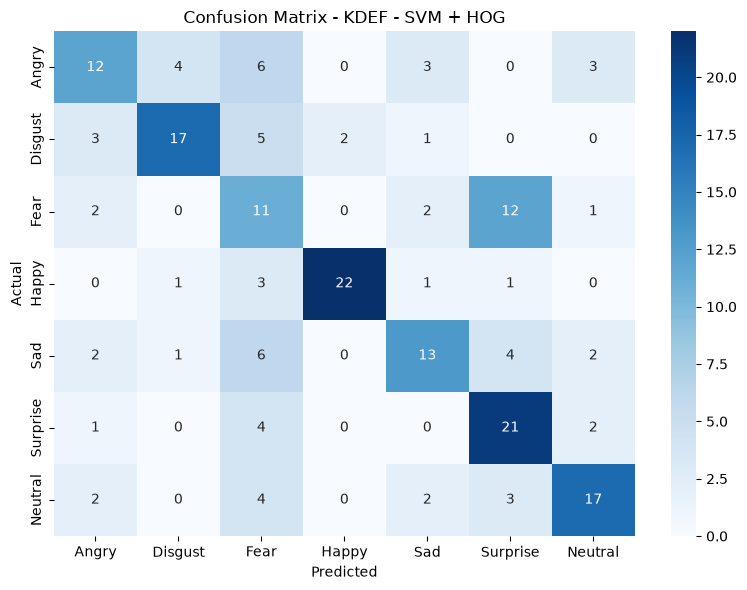

=== Logistic Regression + HOG ===
Accuracy: 0.56
Balanced accuracy: 0.56
Macro F1: 0.56
              precision    recall  f1-score   support

       Angry       0.58      0.39      0.47        28
     Disgust       0.79      0.54      0.64        28
        Fear       0.34      0.54      0.42        28
       Happy       0.91      0.75      0.82        28
         Sad       0.42      0.39      0.41        28
    Surprise       0.50      0.64      0.56        28
     Neutral       0.62      0.64      0.63        28

    accuracy                           0.56       196
   macro avg       0.60      0.56      0.56       196
weighted avg       0.60      0.56      0.56       196



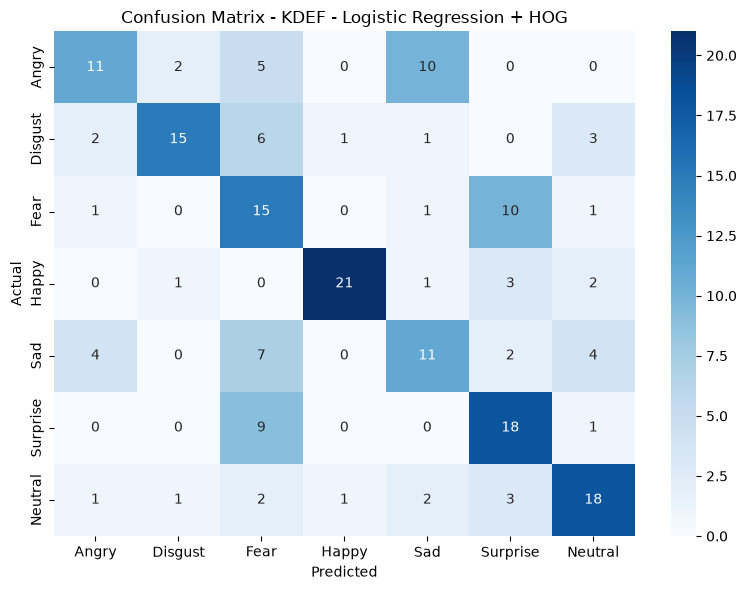

=== Random Forest + HOG ===
Accuracy: 0.63
Balanced accuracy: 0.63
Macro F1: 0.62
              precision    recall  f1-score   support

       Angry       0.85      0.61      0.71        28
     Disgust       0.76      0.68      0.72        28
        Fear       0.44      0.25      0.32        28
       Happy       0.70      0.93      0.80        28
         Sad       0.67      0.43      0.52        28
    Surprise       0.49      0.79      0.60        28
     Neutral       0.60      0.75      0.67        28

    accuracy                           0.63       196
   macro avg       0.64      0.63      0.62       196
weighted avg       0.64      0.63      0.62       196



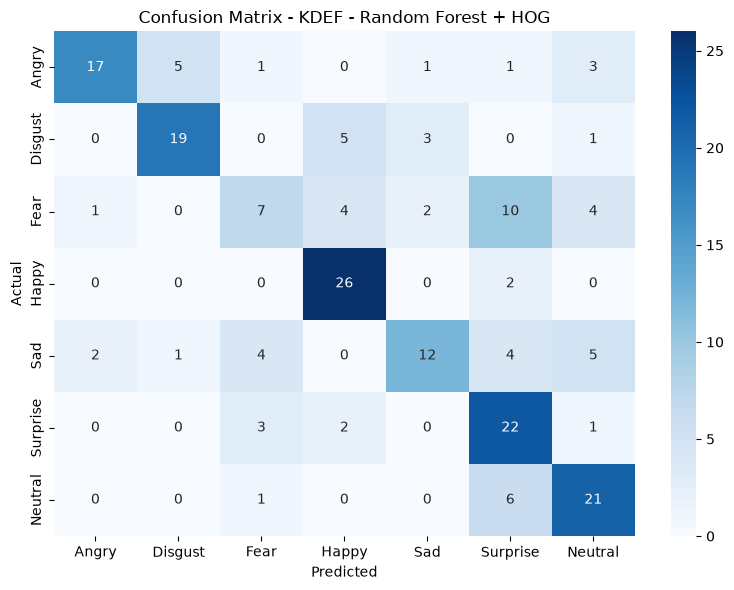

In [8]:
def evaluate(name, model, X, y):
    y_pred = model.predict(X)
    result = {
        "Model": name,
        "Accuracy": accuracy_score(y, y_pred),
        "Balanced accuracy": balanced_accuracy_score(y, y_pred),
        "Macro F1": f1_score(y, y_pred, average='macro'),
    }

    print(f"=== {name} ===")
    print(f"Accuracy: {result['Accuracy']:.2f}")
    print(f"Balanced accuracy: {result['Balanced accuracy']:.2f}")
    print(f"Macro F1: {result['Macro F1']:.2f}")
    print(classification_report(y, y_pred, labels=range(7), target_names=class_names, zero_division=0))

    conf_matrix = confusion_matrix(y, y_pred, labels=range(7))
    plt.figure(figsize=(8, 6))
    sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.title(f"Confusion Matrix - KDEF - {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.savefig(f"figures/KDEF {name} Confusion Matrix.png")
    plt.show()
    return result


results = [evaluate(name, model, hog_test, y_test) for name, model in models.items()]

## 2.7 Cross-Validation 
Only 14 subjects are in the test set (196 images). We propose to use CV for this small data set reason.

In [9]:
cv = GroupKFold(n_splits=5)
scoring = {"Accuracy": "accuracy", "Balanced accuracy": "balanced_accuracy", "Macro F1": "f1_macro"}

cv_rows = []
for name, model in models.items():
    scores = cross_validate(model, hog_train, y_train, groups=groups_train, cv=cv, scoring=scoring)
    row = {"Model": name}
    for metric in scoring:
        s = scores[f"test_{metric}"]
        row[f"CV {metric}"] = f"{s.mean():.2f} ± {s.std():.2f}"
    cv_rows.append(row)

pd.DataFrame(cv_rows).set_index("Model")

,CV Accuracy,CV Balanced accuracy,CV Macro F1
Model,,,
SVM + HOG,0.65 ± 0.05,0.65 ± 0.05,0.64 ± 0.05
Logistic Regression + HOG,0.63 ± 0.03,0.63 ± 0.03,0.62 ± 0.03
Random Forest + HOG,0.64 ± 0.03,0.64 ± 0.03,0.62 ± 0.03


## 2.8 FER2013 Reference 
Reuse of the same pipeline.

In [10]:
fer_train = pd.read_csv("./data/fer2013_train.csv")
fer_valid = pd.read_csv("./data/fer2013_validation.csv")

def fer_images(dataFrame):
    return np.array([np.fromstring(pixels, sep=' ').reshape(48, 48) for pixels in dataFrame['pixels']])

hog_fer_train = extractHOG(fer_images(fer_train))
hog_fer_valid = extractHOG(fer_images(fer_valid))

y_fer_train = fer_train['emotion'].values
y_fer_valid = fer_valid['emotion'].values

fer_pred = {}
for name, model in models.items():
    fer_model = clone(model).fit(hog_fer_train, y_fer_train)
    fer_pred[name] = fer_model.predict(hog_fer_valid)
    print(f"{name} trained on FER2013")

SVM + HOG trained on FER2013
Logistic Regression + HOG trained on FER2013
Random Forest + HOG trained on FER2013


## 2.9 Model Ranking

In [11]:
kdef_pred = {name: model.predict(hog_test) for name, model in models.items()}

rank_rows = []
for name in models:
    rank_rows.append({
        "Model": name,
        "FER2013 accuracy": accuracy_score(y_fer_valid, fer_pred[name]),
        "FER2013 macro F1": f1_score(y_fer_valid, fer_pred[name], average='macro'),
        "KDEF accuracy": accuracy_score(y_test, kdef_pred[name]),
        "KDEF macro F1": f1_score(y_test, kdef_pred[name], average='macro'),
    })

ranking = pd.DataFrame(rank_rows).set_index("Model")
ranking["FER2013 rank"] = ranking["FER2013 macro F1"].rank(ascending=False, method="min").astype(int)
ranking["KDEF rank"] = ranking["KDEF macro F1"].rank(ascending=False, method="min").astype(int)
ranking.round(2)

,FER2013 accuracy,FER2013 macro F1,KDEF accuracy,KDEF macro F1,FER2013 rank,KDEF rank
Model,,,,,,
SVM + HOG,0.54,0.50,0.58,0.58,1,2
Logistic Regression + HOG,0.43,0.39,0.56,0.56,2,3
Random Forest + HOG,0.45,0.39,0.63,0.62,3,1


## 2.10 Emotions Transfer

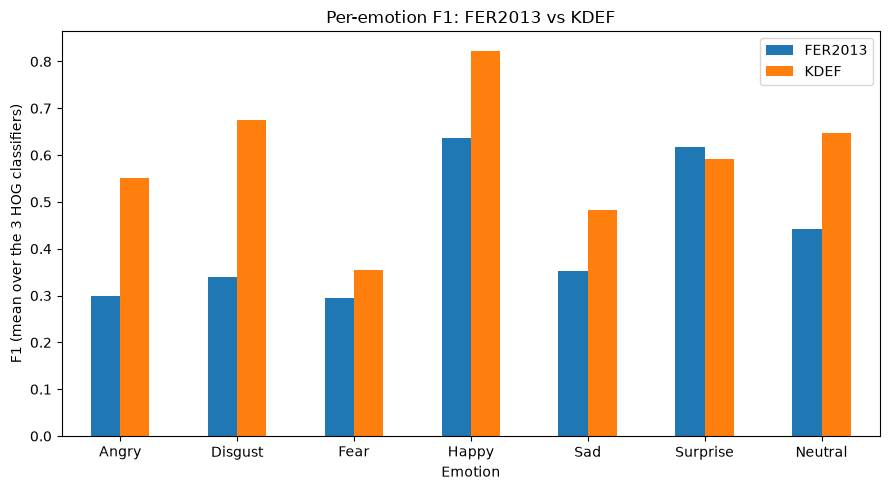

,FER2013,KDEF,Difference (KDEF - FER2013)
Emotion,,,
Angry,0.30,0.55,0.25
Disgust,0.34,0.67,0.33
Fear,0.29,0.35,0.06
Happy,0.64,0.82,0.19
Sad,0.35,0.48,0.13
Surprise,0.62,0.59,-0.03
Neutral,0.44,0.65,0.21


In [12]:
per_class = []
for name in models:
    f1_fer = f1_score(y_fer_valid, fer_pred[name], labels=range(7), average=None)
    f1_kdef = f1_score(y_test, kdef_pred[name], labels=range(7), average=None)

    for c in range(7):
        per_class.append({"Emotion": class_names[c], "Model": name,
                          "FER2013": f1_fer[c], "KDEF": f1_kdef[c]})

per_class = pd.DataFrame(per_class)
emotion_f1 = per_class.groupby("Emotion")[["FER2013", "KDEF"]].mean().reindex(class_names)
emotion_f1["Difference (KDEF - FER2013)"] = emotion_f1["KDEF"] - emotion_f1["FER2013"]

ax = emotion_f1[["FER2013", "KDEF"]].plot.bar(figsize=(9, 5), rot=0)
ax.set_ylabel("F1 (mean over the 3 HOG classifiers)")
ax.set_title("Per-emotion F1: FER2013 vs KDEF")

plt.tight_layout()
plt.savefig("figures/KDEF vs FER2013 per-emotion F1.png")
plt.show()

emotion_f1.round(2)